# Estadísticas globales del Grupo A — 2026

Estadísticas de **toda la zona**, organizadas en dos partes dentro de
`outputs/temporadas/2026/global_grupo_a/liga/`:

- **`temporada/`** — rankings y tendencias de toda la temporada (una sola vez).
- **`fechas/fecha_01 … fecha_36/`** — el **mejor 11 (con banco de 10)** de cada fecha,
  cada uno en su carpeta. Las fechas que todavía no se jugaron quedan con la carpeta creada.

In [1]:
import os, sys
%load_ext autoreload
%autoreload 2
if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd(); sys.path.insert(0, PROJECT_ROOT)
import config
from src.analysis import liga
from src.visualization import liga as vliga
from IPython.display import Image, display
def show(p):
    if p and os.path.exists(p): display(Image(filename=p))

## 1. Configuración

In [2]:
SEASON  = '2026'
ROUNDS  = range(1, 37)      # fechas a procesar (se crean las 36 carpetas)
VER_FECHA = 34           # fecha cuyo mejor 11 querés ver acá abajo
TEMP_DIR = config.group_season_stats_dir(SEASON); os.makedirs(TEMP_DIR, exist_ok=True)
print('Temporada ->', TEMP_DIR)
print('Fechas    ->', config.group_league_dir(SEASON) + r'\fechas\fecha_NN')

Temporada -> c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\global_grupo_a\liga\temporada
Fechas    -> c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\global_grupo_a\liga\fechas\fecha_NN


## 2. Temporada: tabla resumen + rankings ofensivo/defensivo

,equipo,pj,V,E,D,pts,gf,gc,xgf_pp,xgc_pp
0,Club Ferro Carril Oeste,34,19,8,7,65,38,28,1.36,0.81
1,Godoy Cruz,34,17,9,8,60,48,32,1.55,0.94
2,Deportivo Morón,33,17,6,10,57,50,35,1.24,0.92
3,Club Atlético Colón,34,14,12,8,54,41,27,1.30,0.89
4,Deportivo Madryn,32,14,10,8,52,44,27,1.16,1.13
5,Gimnasia Jujuy,32,14,10,8,52,49,40,1.49,1.40
6,Ciudad de Bolívar,34,13,12,9,51,30,29,0.90,1.33
7,Almirante Brown,34,12,12,10,48,28,24,0.97,1.03
8,Estudiantes de Buenos Aires,33,13,9,11,48,34,32,1.26,1.05
9,Chaco For Ever,34,11,10,13,43,36,35,1.09,1.11


,equipo,npxgf_pp,npxgc_pp,xgotf_pp,xgotc_pp,cabeza_f_pp,cabeza_c_pp,pelota_parada_f_pp,pelota_parada_c_pp,palos_f,palos_c,penales_f,penales_convertidos,penales_c,km_pp,partidos_con_km
0,Club Ferro Carril Oeste,1.25,0.74,1.14,0.80,1.88,1.59,4.44,3.32,15,5,5,4,3,103.06,1
1,Godoy Cruz,1.40,0.90,1.36,0.79,1.94,1.68,4.12,3.82,7,5,7,4,2,100.56,1
2,Deportivo Morón,1.08,0.82,1.37,1.00,1.73,1.21,4.27,3.45,7,2,7,7,4,NaN,0
3,Club Atlético Colón,1.17,0.85,1.35,0.89,2.38,1.18,4.18,3.35,8,7,6,5,2,NaN,0
4,Deportivo Madryn,1.11,1.03,1.07,0.97,2.00,1.72,4.31,3.59,4,6,2,2,4,NaN,0
5,Gimnasia Jujuy,1.44,1.38,1.39,1.23,2.28,2.62,4.84,3.84,7,4,2,1,1,89.02,1
6,Ciudad de Bolívar,0.83,1.28,0.86,1.13,2.06,2.15,3.29,5.44,4,3,3,1,2,NaN,0
7,Almirante Brown,0.93,0.99,0.96,0.97,1.47,1.62,3.65,3.71,2,11,2,2,2,NaN,0
8,Estudiantes de Buenos Aires,1.14,1.02,1.07,0.86,1.30,1.79,3.48,4.15,5,12,5,5,1,NaN,0
9,Chaco For Ever,0.94,1.05,1.08,1.22,1.47,2.35,3.65,3.59,3,2,7,5,3,NaN,0


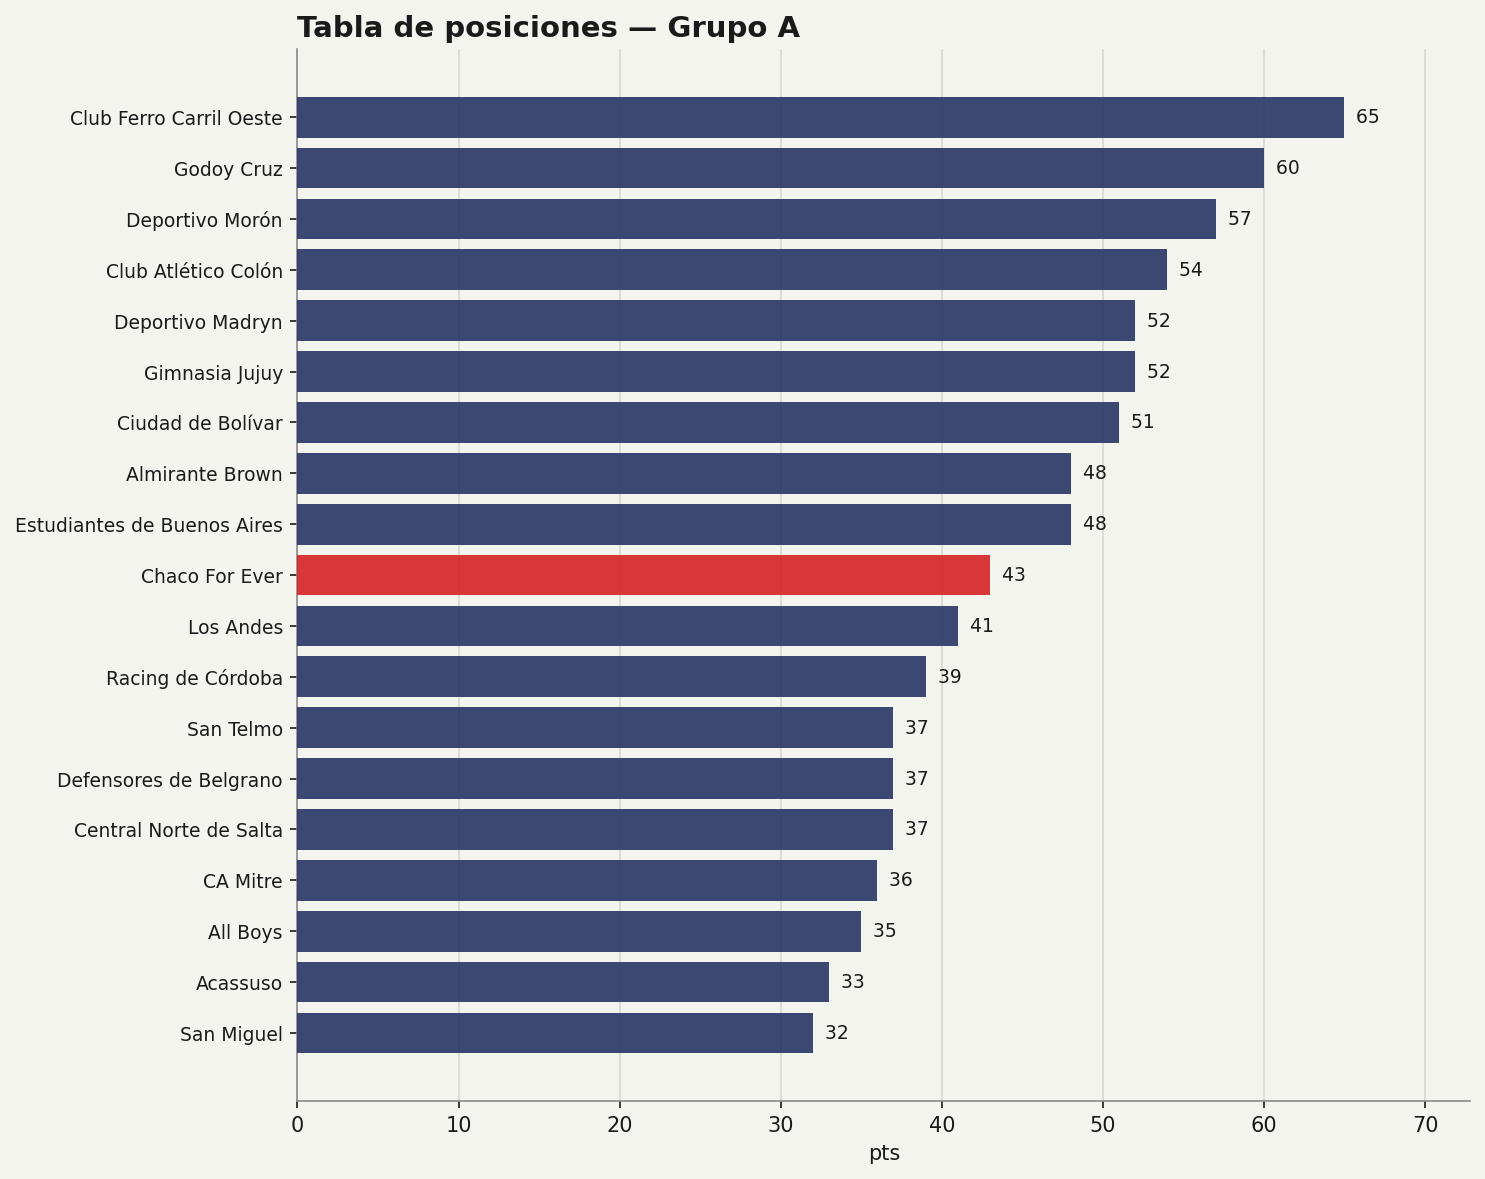

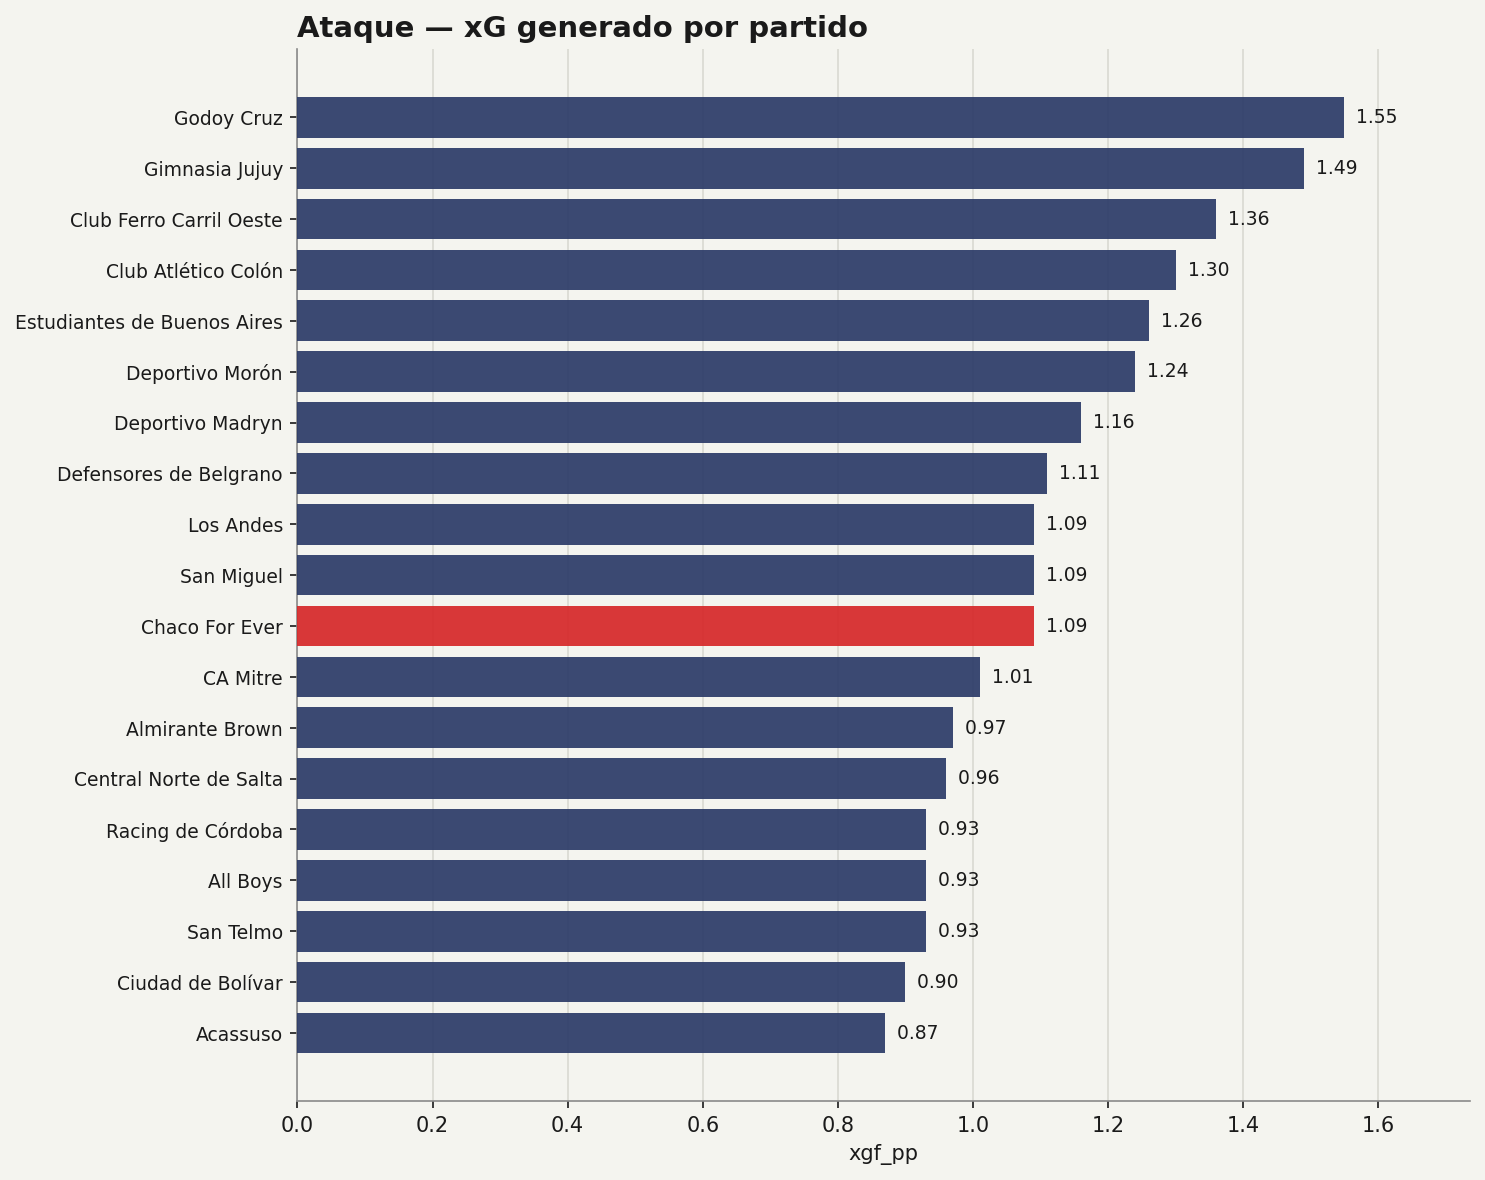

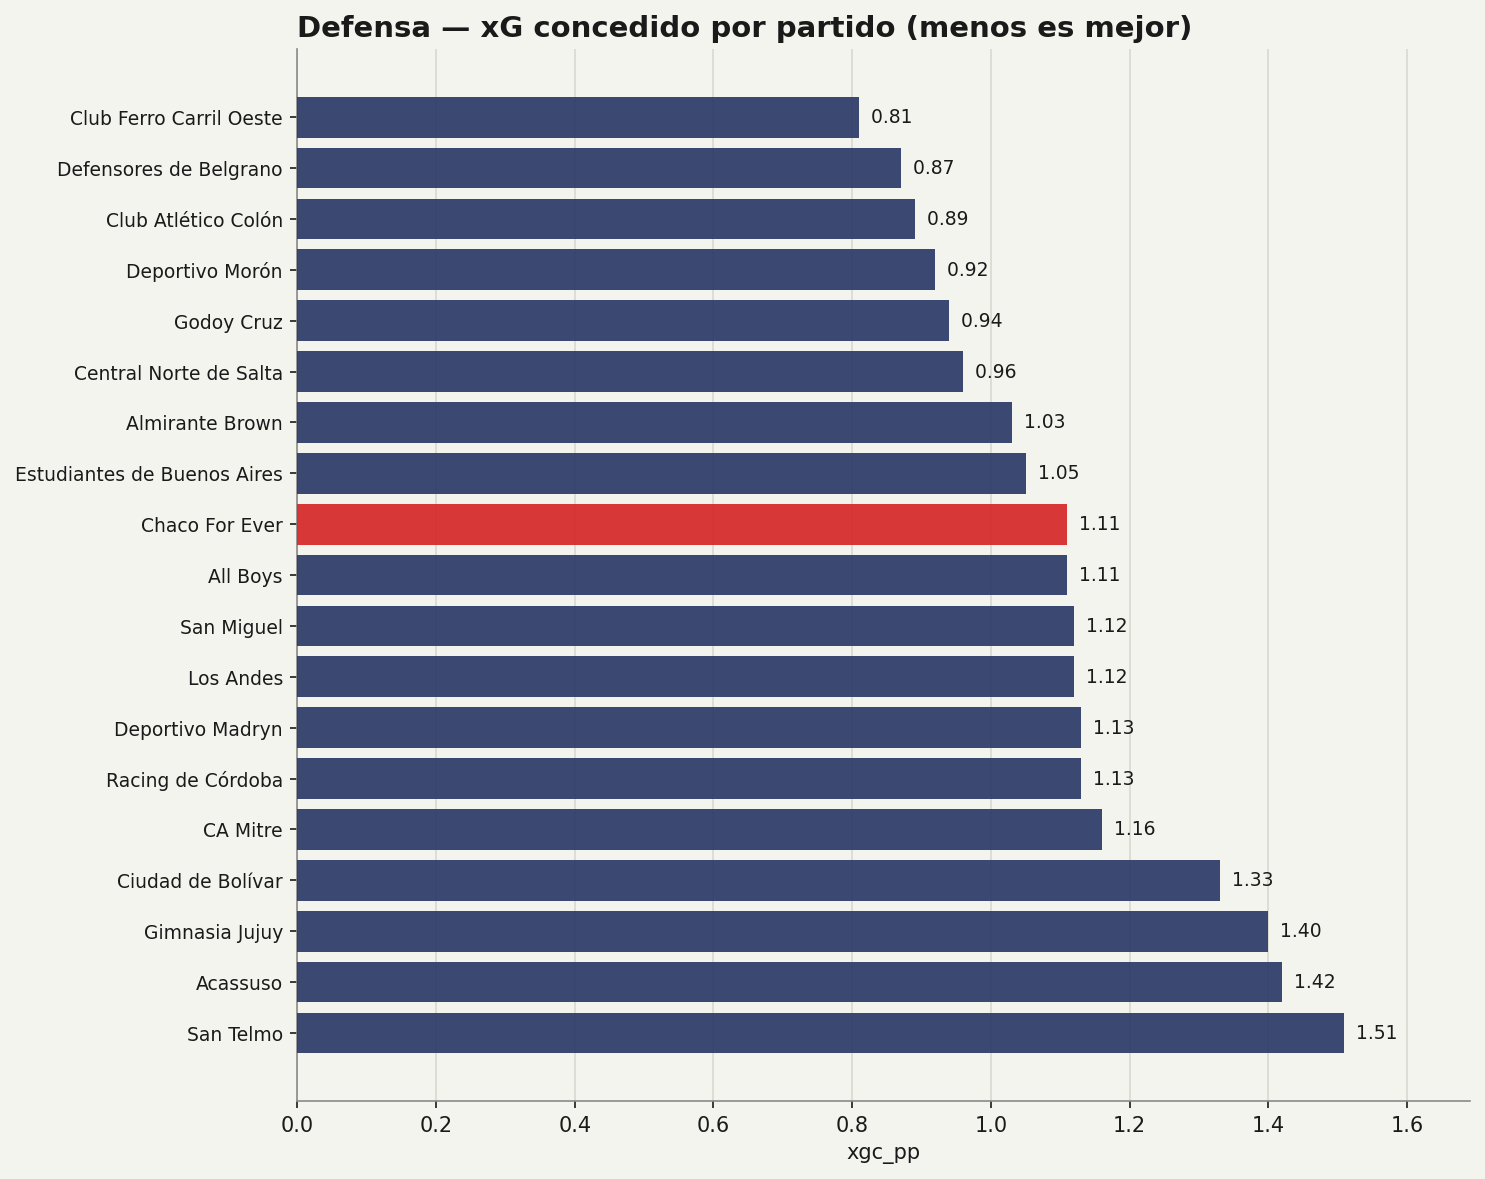

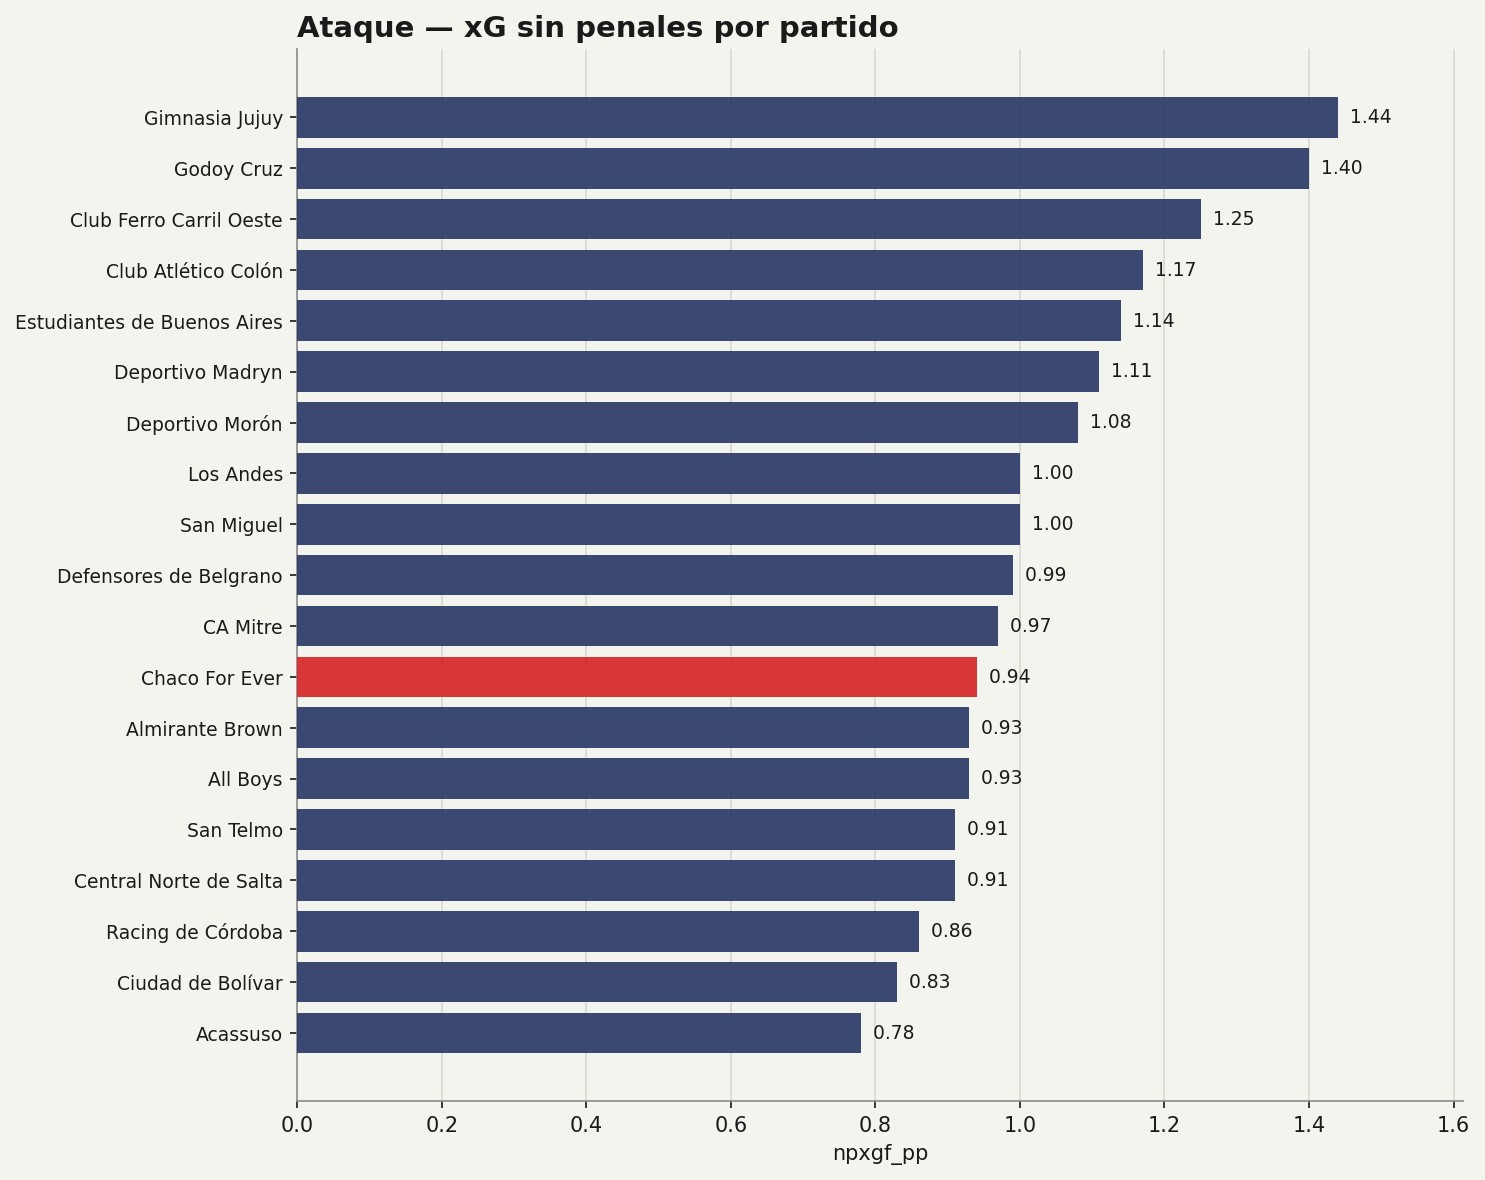

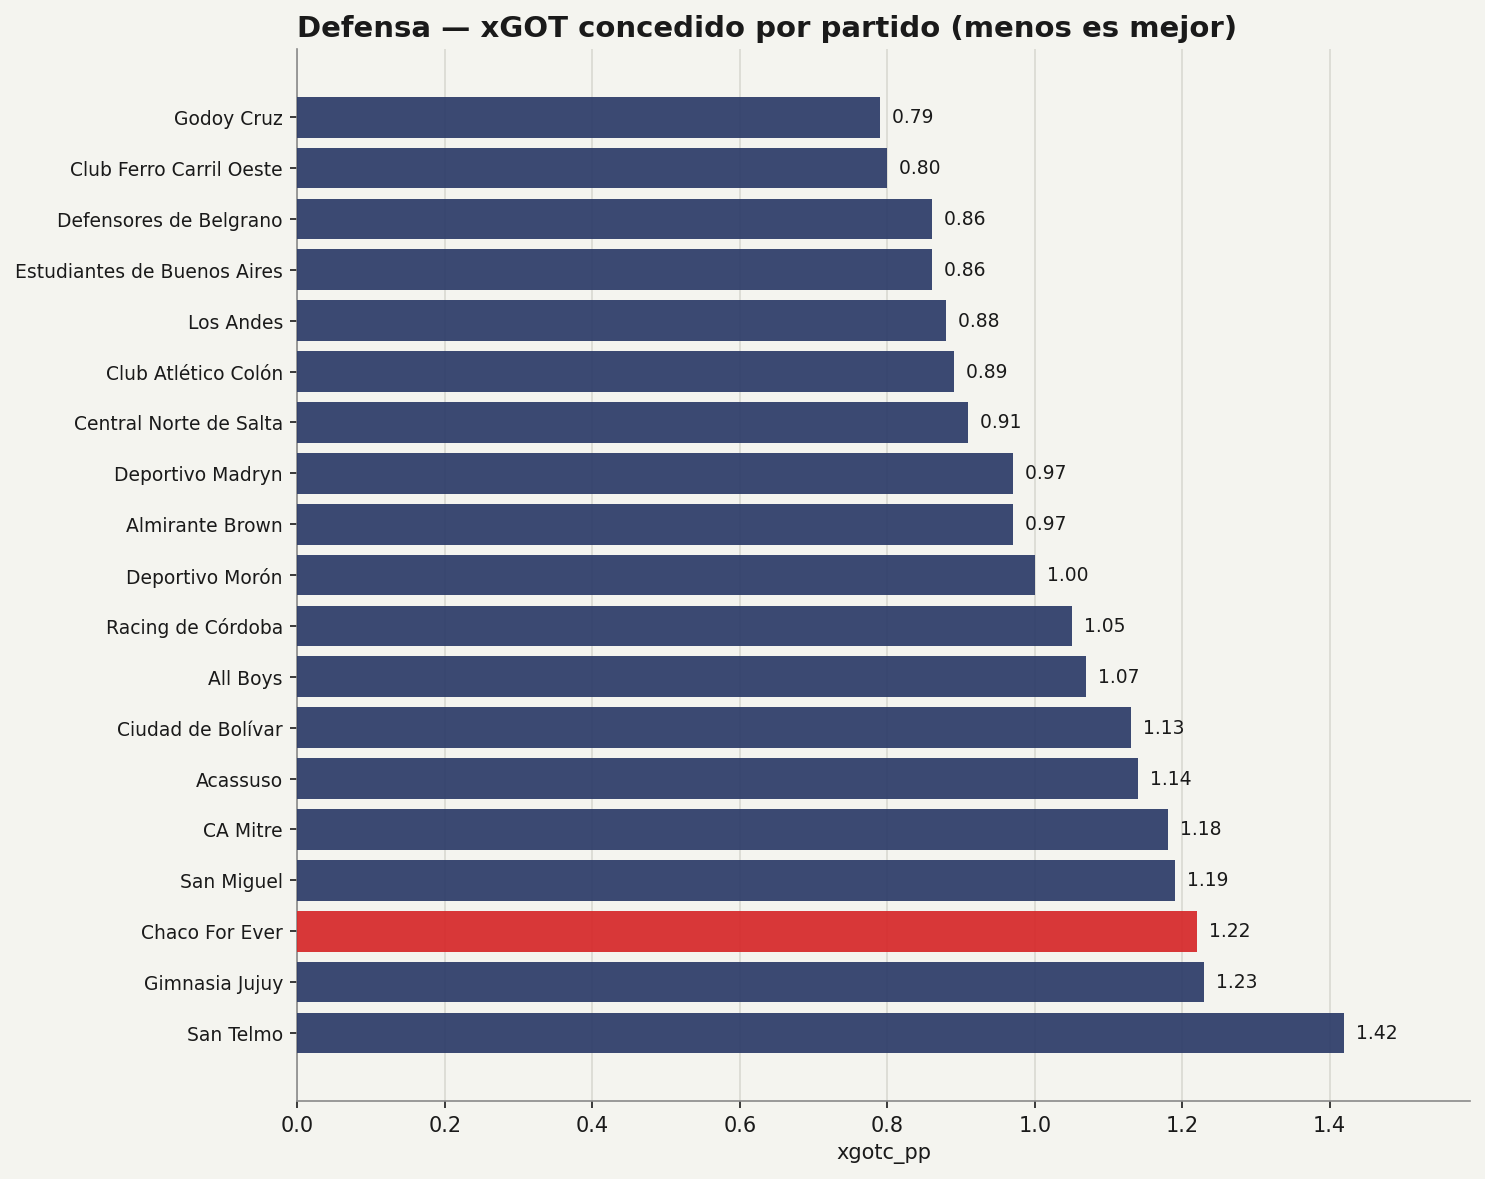

In [3]:
tsum = liga.team_summary_table(SEASON)
tsum.to_csv(os.path.join(TEMP_DIR, 'tabla_resumen_grupo_a.csv'), index=False)
display(tsum[['equipo','pj','V','E','D','pts','gf','gc','xgf_pp','xgc_pp']])

vliga.plot_ranking_bars(tsum, 'pts', title='Tabla de posiciones — Grupo A',
                        fmt='{:.0f}', save_path=os.path.join(TEMP_DIR, 'ranking_puntos.png'))
vliga.plot_ranking_bars(tsum, 'xgf_pp', title='Ataque — xG generado por partido',
                        save_path=os.path.join(TEMP_DIR, 'ranking_ofensivo.png'))
vliga.plot_ranking_bars(tsum, 'xgc_pp', ascending=True,
                        title='Defensa — xG concedido por partido (menos es mejor)',
                        save_path=os.path.join(TEMP_DIR, 'ranking_defensivo.png'))
# Del shotmap tiro por tiro y del JSON crudo: npxG, xGOT, cabeza, pelota
# parada, palos, penales y km (km solo en los pocos partidos con tracking).
display(tsum[['equipo', 'npxgf_pp', 'npxgc_pp', 'xgotf_pp', 'xgotc_pp',
              'cabeza_f_pp', 'cabeza_c_pp', 'pelota_parada_f_pp', 'pelota_parada_c_pp',
              'palos_f', 'palos_c', 'penales_f', 'penales_convertidos', 'penales_c',
              'km_pp', 'partidos_con_km']])
vliga.plot_ranking_bars(tsum, 'npxgf_pp', title='Ataque — xG sin penales por partido',
                        save_path=os.path.join(TEMP_DIR, 'ranking_npxg.png'))
vliga.plot_ranking_bars(tsum, 'xgotc_pp', ascending=True,
                        title='Defensa — xGOT concedido por partido (menos es mejor)',
                        save_path=os.path.join(TEMP_DIR, 'ranking_xgot_concedido.png'))
for f in ['ranking_puntos.png','ranking_ofensivo.png','ranking_defensivo.png',
          'ranking_npxg.png','ranking_xgot_concedido.png']:
    show(os.path.join(TEMP_DIR, f))

## 3. Mejor 11 de CADA fecha (1–36) con banco de 10\nCrea las 36 carpetas y genera el gráfico en las que ya tienen datos.

  fecha  1: ✔ (11 titulares, 10 suplentes)
  fecha  2: ✔ (11 titulares, 10 suplentes)
  fecha  3: ✔ (11 titulares, 10 suplentes)
  fecha  4: ✔ (11 titulares, 10 suplentes)
  fecha  5: ✔ (11 titulares, 10 suplentes)
  fecha  6: ✔ (11 titulares, 10 suplentes)
  fecha  7: ✔ (11 titulares, 10 suplentes)
  fecha  8: ✔ (11 titulares, 10 suplentes)
  fecha  9: ✔ (11 titulares, 10 suplentes)
  fecha 10: ✔ (11 titulares, 10 suplentes)
  fecha 11: ✔ (11 titulares, 10 suplentes)
  fecha 12: ✔ (11 titulares, 10 suplentes)
  fecha 13: ✔ (11 titulares, 10 suplentes)
  fecha 14: ✔ (11 titulares, 10 suplentes)
  fecha 15: ✔ (11 titulares, 10 suplentes)
  fecha 16: ✔ (11 titulares, 10 suplentes)
  fecha 17: ✔ (11 titulares, 10 suplentes)
  fecha 18: ✔ (11 titulares, 10 suplentes)
  fecha 19: ✔ (11 titulares, 10 suplentes)
  fecha 20: ✔ (11 titulares, 10 suplentes)
  fecha 21: ✔ (11 titulares, 10 suplentes)
  fecha 22: ✔ (11 titulares, 10 suplentes)
  fecha 23: ✔ (11 titulares, 10 suplentes)
  fecha 24:

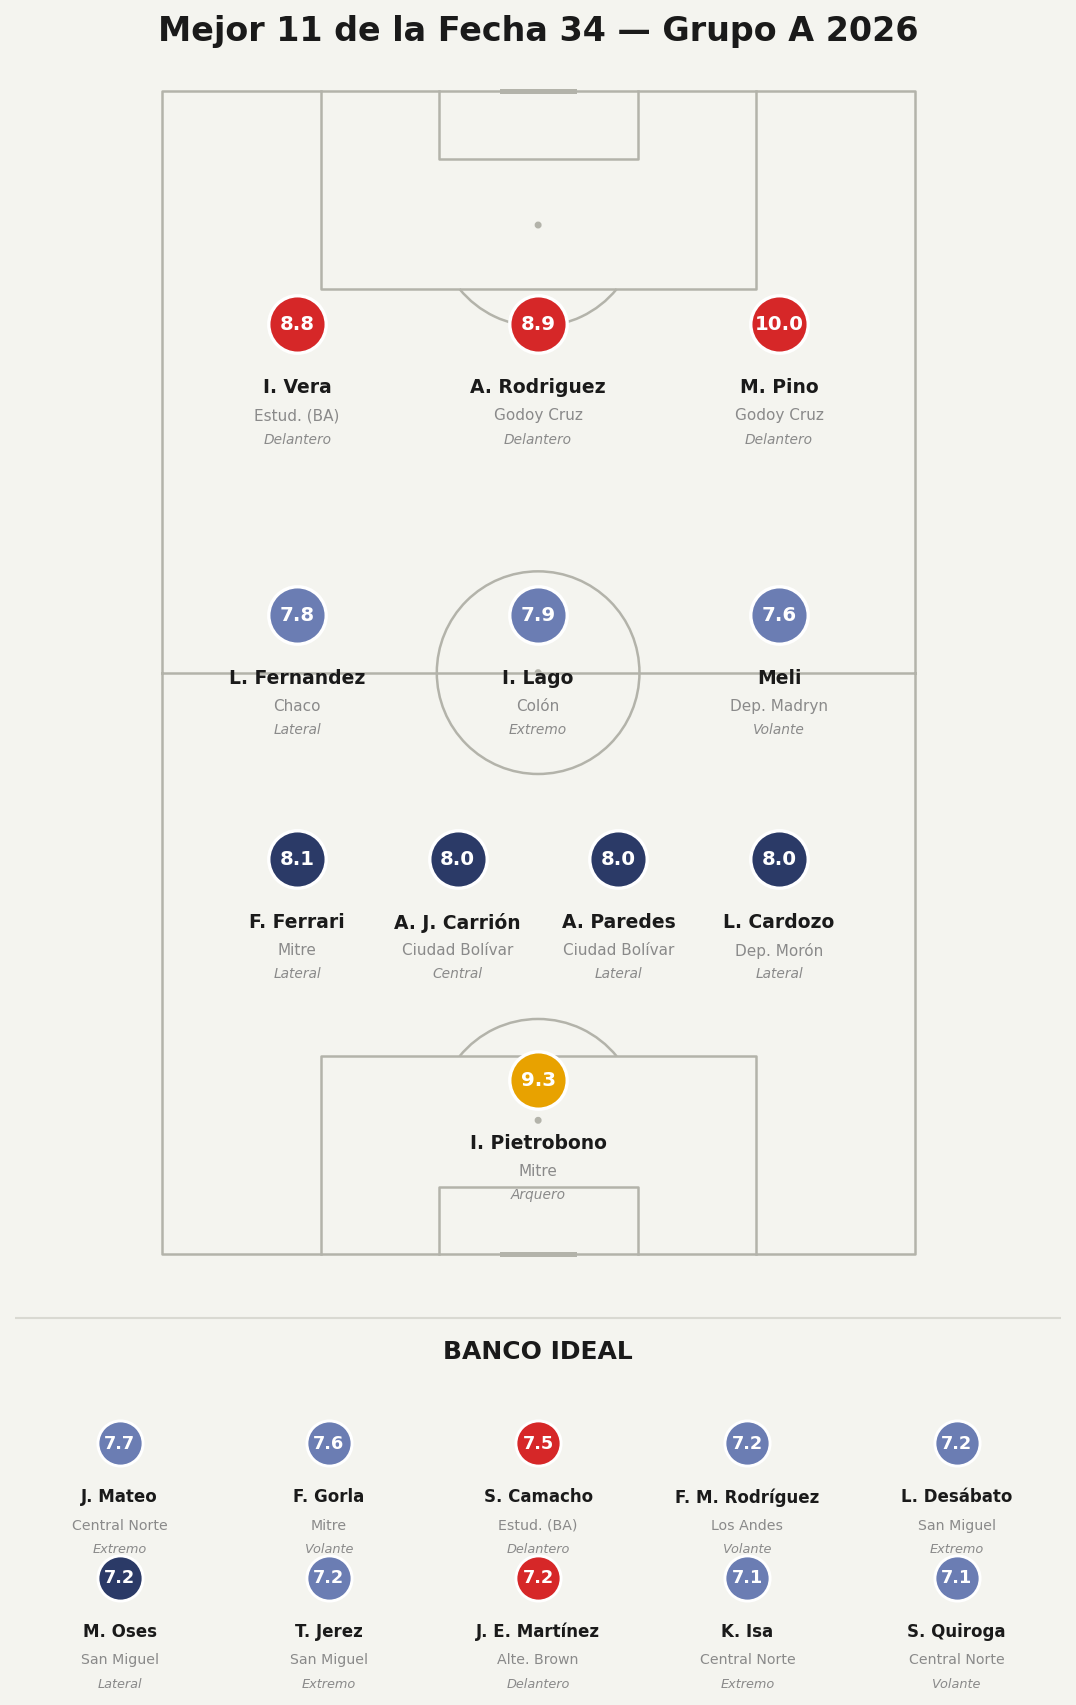

In [4]:
hechas = liga.generate_all_rounds(SEASON, rounds=ROUNDS, verbose=True)

# Ver una fecha puntual:
p = os.path.join(config.group_round_dir(VER_FECHA, SEASON), 'mejor_11.png')
print('\nMostrando fecha', VER_FECHA)
show(p)

## 4. ¿Se juega por el medio? — origen de los remates (temporada)

,equipo,zona,n,pct
0,LIGA,area_centro,2895,41.1
1,LIGA,area_lateral,1086,15.4
2,LIGA,fuera_centro,1919,27.3
3,LIGA,fuera_lateral,1137,16.2


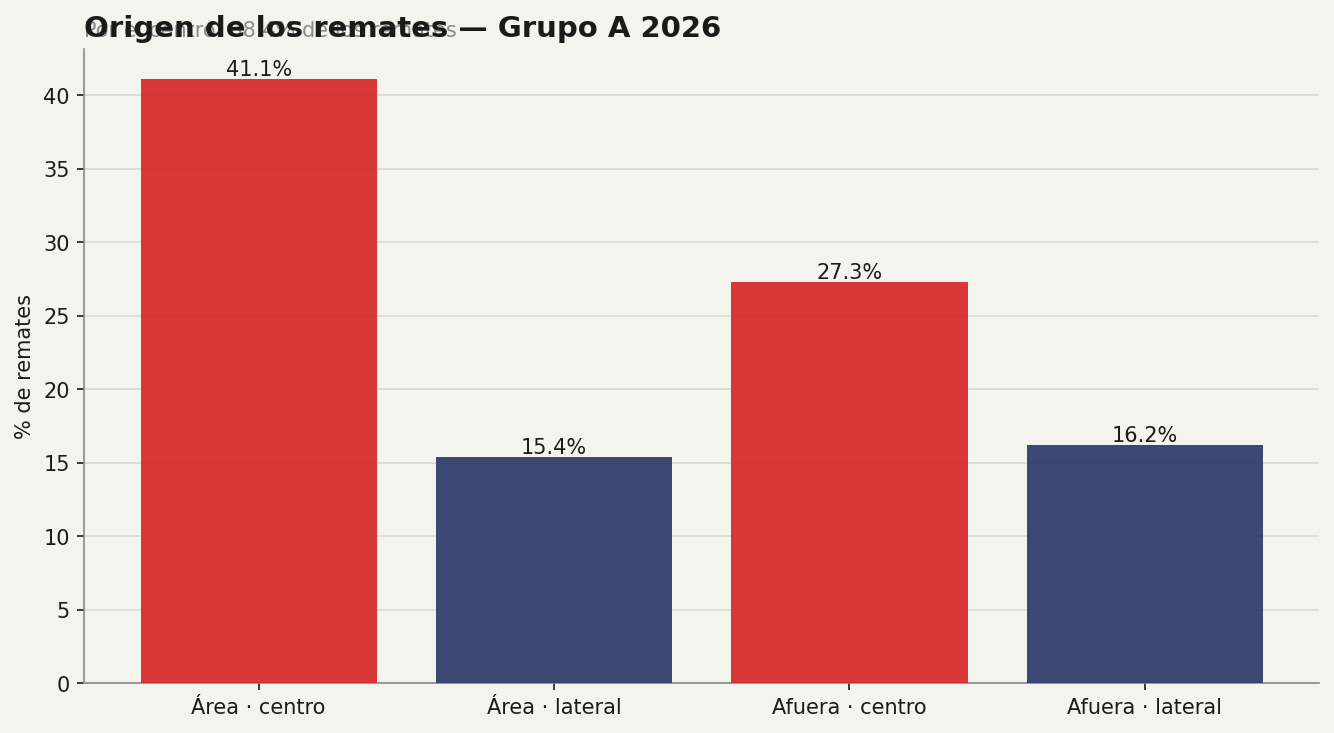


De la temporada: 68.4% de los remates del grupo nacen por el corredor central.


In [5]:
so = liga.shot_origin_distribution(SEASON, by_team=False)
so.to_csv(os.path.join(TEMP_DIR, 'origen_remates_liga.csv'), index=False)
display(so)
p = os.path.join(TEMP_DIR, 'origen_remates.png')
vliga.plot_shot_origin(so, season=SEASON, save_path=p)
show(p)
central = round(so[so.zona.str.endswith('centro')]['n'].sum() / so['n'].sum() * 100, 1)
print(f'\nDe la temporada: {central}% de los remates del grupo nacen por el corredor central.')

## Notas
- Para ver otra fecha: cambiá `VER_FECHA`. Todas quedan guardadas en `liga/fechas/fecha_NN/`
  (`mejor_11.png` + `mejor_11.csv` + `banco.csv`).
- Al cerrar cada fecha nueva, volvé a correr la sección 3: genera solo lo que falte.
- `liga.shot_origin_distribution(SEASON, by_team=True)` desglosa el origen por equipo.